# Walkthrough: cash-flow forecaster with spikes and holidays

The pieces behind `scripts/run_pipeline.py`, with charts:

1. **The data:** three simulated corridors with random spikes, payroll Fridays and holidays.
2. **Random spikes:** how they inflate a simple baseline, and how a Gaussian mixture finds them.
3. **Holidays:** effects learned from history vs the true effects.
4. **Payroll Fridays:** why Fourier seasonality catches what a weekday pattern can't.
5. **The backtest:** all five versions, and what each step adds.

All core logic lives in `src/`; this notebook only calls it.

In [1]:
import os, sys, warnings
os.environ.setdefault('OMP_NUM_THREADS', '1')
warnings.filterwarnings('ignore', message='IProgress not found')  # tqdm notice from Prophet
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from cashflow_forecaster import generate_flows, SeasonalWeekday, SpikeAdjusted, HolidayAdjusted
from cashflow_forecaster.models import ProphetFourier
from cashflow_forecaster.data import TRUE_HOLIDAY_EFFECTS, TRUE_WEEKDAY_FACTORS, SCHEDULED_FACTOR
from cashflow_forecaster.evaluate import backtest_all, ladder_table
from cashflow_forecaster import plots   # also sets the chart style
from cashflow_forecaster.plots import COLORS, INK, INK_2, GRID

def millions(ax):
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${v/1e6:,.0f}M'))

## 1. The data
Three corridors (U.S. to Mexico, the Philippines and India), each the product of known parts. Random spikes, payroll Fridays and holiday positions are kept as columns, so we can check what the models recover.

In [2]:
flows = generate_flows()
mx = flows[flows.corridor == 'MX']
mx[mx.date.between('2025-05-05', '2025-05-12')][['date', 'volume', 'holiday_name', 'holiday_offset', 'holiday_factor', 'is_scheduled', 'is_spike']]

,date,volume,holiday_name,holiday_offset,holiday_factor,is_scheduled,is_spike
1585,2025-05-05,5.161436e+07,NaN,NaN,1.00,False,False
1586,2025-05-06,4.504695e+07,NaN,NaN,1.00,False,False
1587,2025-05-07,4.881831e+07,Día de las Madres,-3.0,1.25,False,False
1588,2025-05-08,5.839301e+07,Día de las Madres,-2.0,1.40,False,False
1589,2025-05-09,1.385759e+08,Día de las Madres,-1.0,1.55,True,False
1590,2025-05-10,2.007858e+07,Día de las Madres,0.0,0.60,False,False
1591,2025-05-11,8.616876e+07,Día de las Madres,1.0,1.20,False,True
1592,2025-05-12,4.768705e+07,NaN,NaN,1.00,False,False


Three months of the Mexico corridor. The weekly rhythm is visible, with three kinds of unusual days on top of it.

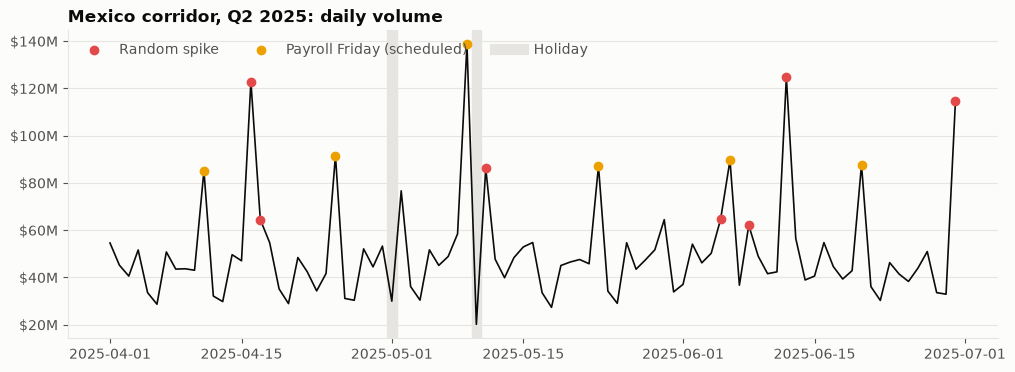

In [3]:
s = mx[mx.date.between('2025-04-01', '2025-06-30')].set_index('date')
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(s.index, s.volume, color=INK, lw=1.2, zorder=3)
for d in s.index[s.holiday_offset == 0]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=GRID, zorder=0)
ax.scatter(s.index[s.is_spike], s.volume[s.is_spike], color='#e34948', s=36, zorder=4, label='Random spike')
sched = s.is_scheduled & ~s.is_spike
ax.scatter(s.index[sched], s.volume[sched], color=COLORS['4. Prophet + Fourier'], s=36, zorder=4, label='Payroll Friday (scheduled)')
ax.plot([], [], color=GRID, lw=8, label='Holiday')
ax.set_title('Mexico corridor, Q2 2025: daily volume')
ax.legend(ncols=3, loc='upper left')
millions(ax)

## 2. Random spikes inflate the baseline
About 1 day in 10 is a random spike at roughly twice normal volume. A level built from a plain average absorbs them, so the baseline forecasts ordinary days too high. The spike-adjusted model fits a two-component Gaussian mixture on the residuals and re-estimates the baseline without the spike days.

In [4]:
series = mx[['date', 'volume']]
base = SeasonalWeekday().fit(series)
spike = SpikeAdjusted().fit(series)
print(f'baseline level ${base.level_/1e6:.1f}M, clean level ${spike.level_/1e6:.1f}M '
      f'({base.level_/spike.level_ - 1:+.0%} inflation removed)')
print(f'spike probability {spike.spike_prob_:.1%}, average spike size x{spike.spike_multiplier_:.2f}')

baseline level $58.6M, clean level $52.6M (+11% inflation removed)
spike probability 8.4%, average spike size x2.20


The residuals form two groups: ordinary days around zero, and a long tail of spikes. The mixture fits one component to each. The ordinary-day group is wide because this model knows nothing about holidays (the left tail) or payroll Fridays; compare it with the final model's residuals in section 4.

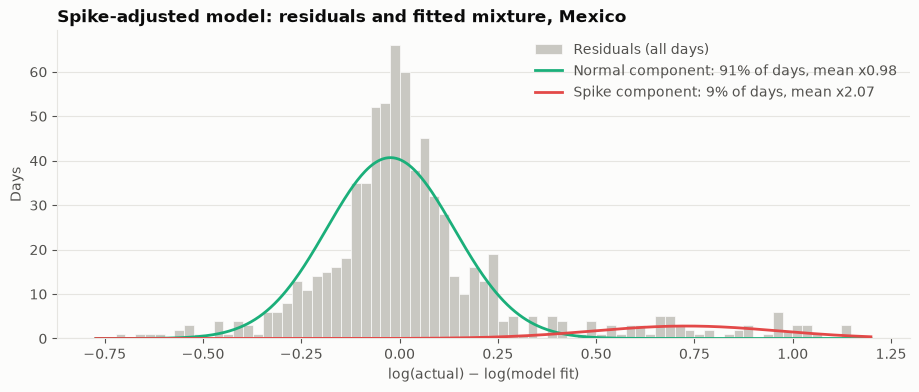

In [5]:
plots.plot_residual_gmm(spike, None, 'Spike-adjusted model: residuals and fitted mixture, Mexico')

Spike cleaning barely changes the weekday factors: the damage random spikes do is to the level, which was too high on every day. Note Friday: both models put it near 1.6 against a true 1.29. Every other Friday is a payroll run at x1.6, and a weekday factor can only average the two kinds of Friday, so payroll Fridays end up under-forecast and ordinary Fridays over-forecast. Section 4 fixes that.

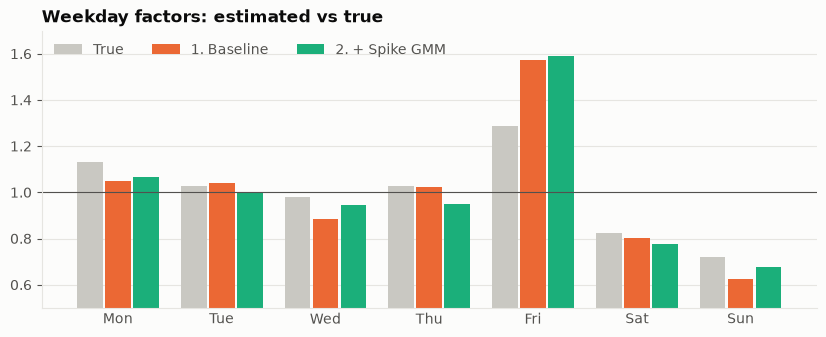

In [6]:
days = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
fig, ax = plt.subplots(figsize=(10, 3.6))
x = np.arange(7); w = 0.27
ax.bar(x - w, TRUE_WEEKDAY_FACTORS, w * 0.92, color='#c9c8c2', label='True', zorder=2)
ax.bar(x, base.weekday_factors_.values, w * 0.92, color=COLORS['1. Baseline'], label='1. Baseline', zorder=2)
ax.bar(x + w, spike.weekday_factors_.values, w * 0.92, color=COLORS['2. + Spike GMM'], label='2. + Spike GMM', zorder=2)
ax.axhline(1, color=INK_2, lw=0.8)
ax.set_xticks(x, days); ax.tick_params(axis='x', length=0)
ax.set_ylim(0.5, 1.7)
ax.set_title('Weekday factors: estimated vs true')
ax.legend(ncols=3, loc='upper left');

## 3. Holiday effects learned from history
Each position in a holiday window (3 to 1 days before a major holiday, the day itself, the day after) gets a multiplicative effect: the median of actual ÷ normal-day fit over past occurrences, shrunk toward 1 when there are few.

In [7]:
full = HolidayAdjusted(country='MX').fit(series)
effects = pd.DataFrame({
    'estimated': full.holiday_effects_.round(3),
    'true': {f'{t}:{o}': v for (t, o), v in TRUE_HOLIDAY_EFFECTS.items()},
    'past occurrences': full.holiday_counts_,
})
effects

,estimated,true,past occurrences
major:-1,1.561,1.55,15
major:-2,1.328,1.40,15
major:-3,1.228,1.25,15
major:0,0.609,0.60,15
major:1,1.177,1.20,15
minor:0,0.633,0.60,26
minor:1,1.177,1.15,26


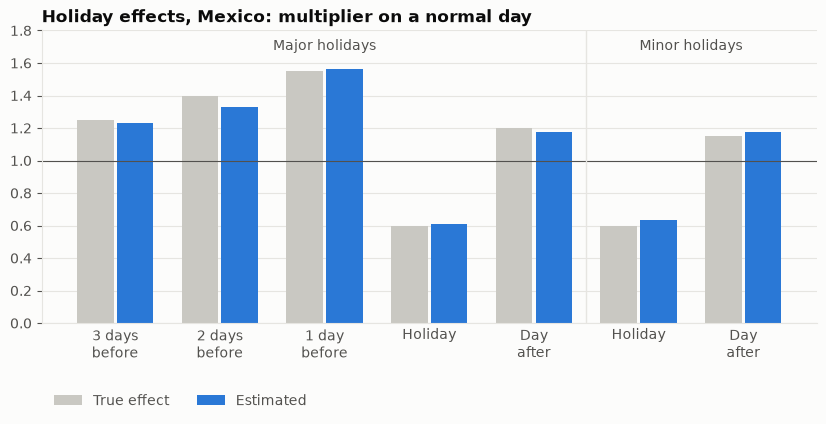

In [8]:
order = ['major:-3', 'major:-2', 'major:-1', 'major:0', 'major:1', 'minor:0', 'minor:1']
labels = ['3 days\nbefore', '2 days\nbefore', '1 day\nbefore', 'Holiday', 'Day\nafter', 'Holiday', 'Day\nafter']
e = effects.reindex(order)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(order)); w = 0.38
ax.bar(x - w/2, e['true'], w * 0.92, color='#c9c8c2', label='True effect', zorder=2)
ax.bar(x + w/2, e['estimated'], w * 0.92, color=COLORS['3. + Holidays'], label='Estimated', zorder=2)
ax.axhline(1, color=INK_2, lw=0.8)
ax.axvline(4.5, color=GRID, lw=1)
ax.text(2, 1.68, 'Major holidays', ha='center', color=INK_2)
ax.text(5.5, 1.68, 'Minor holidays', ha='center', color=INK_2)
ax.set_xticks(x, labels); ax.tick_params(axis='x', length=0)
ax.set_ylim(0, 1.8)
ax.set_title('Holiday effects, Mexico: multiplier on a normal day')
ax.legend(ncols=2, loc='upper left', bbox_to_anchor=(0, -0.2));

## 4. Fourier terms forecast the payroll Fridays
Every other Friday is a payroll run at x1.6. A weekday factor can't tell those Fridays apart from the others, so steps 1-3 average them into one Friday factor. Prophet with a 14-day Fourier seasonality treats them as a repeating pattern and forecasts them. Both models below are trained on data up to 30 June 2025 and forecast the next 8 weeks.

In [9]:
train = series[series.date <= '2025-06-30']
step3 = HolidayAdjusted(country='MX').fit(train)
final = ProphetFourier(country='MX', clean_spikes=True).fit(train)
dates = pd.date_range('2025-07-07', periods=56)
fri = dates[dates.day_of_week == 4]
pd.DataFrame({'payroll': (fri - pd.Timestamp('2021-01-08')).days % 14 == 0,
              'step 3 ($M)': (step3.predict(fri) / 1e6).round(1).values,
              'final ($M)': (final.predict(fri) / 1e6).round(1).values}, index=fri.date)

,payroll,step 3 ($M),final ($M)
2025-07-11,False,70.7,56.9
2025-07-18,True,70.9,90.0
2025-07-25,False,70.9,57.5
2025-08-01,True,80.6,110.1
2025-08-08,False,70.7,56.5
2025-08-15,True,79.6,102.1
2025-08-22,False,70.9,55.9
2025-08-29,True,79.3,99.2


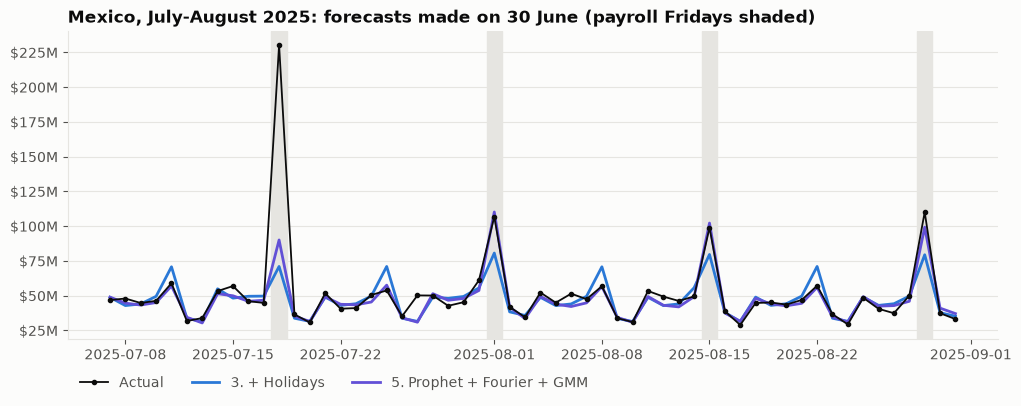

In [10]:
actual = mx.set_index('date').volume.reindex(dates)
payroll = mx.set_index('date').is_scheduled.reindex(dates)
fig, ax = plt.subplots(figsize=(12, 4))
for d in dates[payroll.to_numpy()]:
    ax.axvspan(d - pd.Timedelta(hours=12), d + pd.Timedelta(hours=12), color=GRID, zorder=0)
ax.plot(dates, actual, color=INK, lw=1.3, marker='o', ms=3, label='Actual', zorder=4)
ax.plot(dates, step3.predict(dates), color=COLORS['3. + Holidays'], lw=2, label='3. + Holidays', zorder=3)
ax.plot(dates, final.predict(dates), color=COLORS['5. Prophet + Fourier + GMM'], lw=2, label='5. Prophet + Fourier + GMM', zorder=3)
ax.set_title('Mexico, July-August 2025: forecasts made on 30 June (payroll Fridays shaded)')
ax.legend(ncols=3, loc='upper left', bbox_to_anchor=(0, -0.08))
millions(ax)

Because the mixture in the final model runs on *Prophet's* residuals, which already explain the payroll Fridays, it removes only the random spikes:

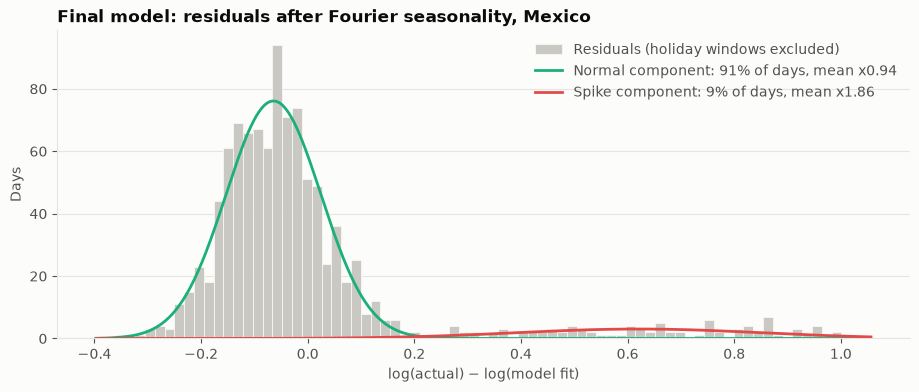

In [11]:
plots.plot_residual_gmm(final, None, 'Final model: residuals after Fourier seasonality, Mexico')

## 5. The backtest: what each version adds
All five versions, walk-forward over 2025, forecasting 7 days ahead on every corridor. Versions 1-3 are refit daily, the Prophet versions weekly. This runs in parallel and takes about a minute. (Results can differ from the README in the second decimal: with only the 7-day horizon, the weekly Prophet refits fall on different days.)

In [12]:
bt = backtest_all(flows, horizons=(7,))
ladder = ladder_table(bt)
money = [c for c in ladder.columns if c not in ('horizon', 'model', 'MSE') and not c.endswith('_pct')]
ladder.assign(**{c: (ladder[c] / 1e6).round(2) for c in money}).drop(columns=['MSE', 'horizon'])

,model,MAE,RMSE,MAE_normal,MAE_spike,MAE_scheduled,MAE_holiday,required_buffer,avg_cash_held,idle_cash_cost_per_year,MAE_vs_previous_pct,MAE_vs_baseline_pct,idle_cash_saving_vs_baseline
0,1. Baseline,8.80,16.24,5.07,36.00,11.04,16.05,64.52,174.71,0.50,NaN,0.0,0.00
1,2. + Spike GMM,7.61,16.09,2.98,38.92,15.40,15.35,73.78,174.22,0.22,-13.6,-13.6,0.29
2,3. + Holidays,6.87,15.39,2.77,38.82,15.40,9.51,70.43,170.69,0.18,-9.6,-21.9,0.32
3,4. Prophet + Fourier,6.37,14.03,3.14,36.14,6.10,9.20,57.88,165.44,0.29,-7.4,-27.6,0.21
4,5. Prophet + Fourier + GMM,5.49,13.98,1.97,38.21,4.29,8.92,62.37,163.86,0.10,-13.8,-37.6,0.40


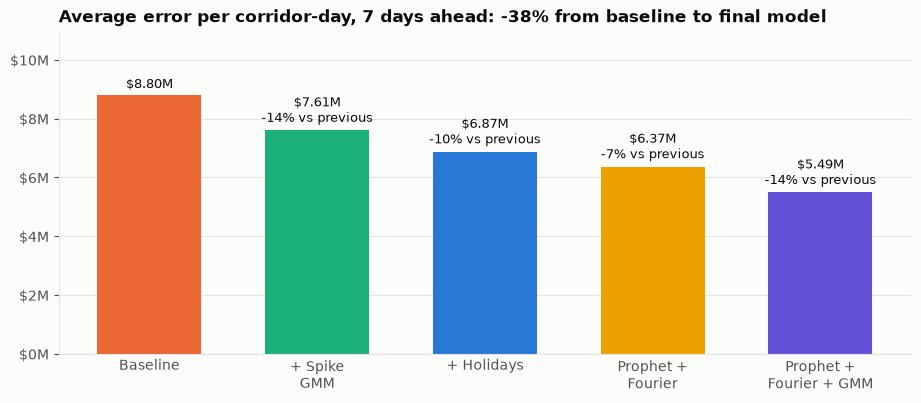

In [13]:
plots.plot_accuracy_steps(ladder, 7, None)

Breaking the error down by type of day shows which step fixed what: spike cleaning helps ordinary days, holiday effects help holiday windows, Fourier terms help payroll Fridays. Random spikes stay unpredictable for every version.

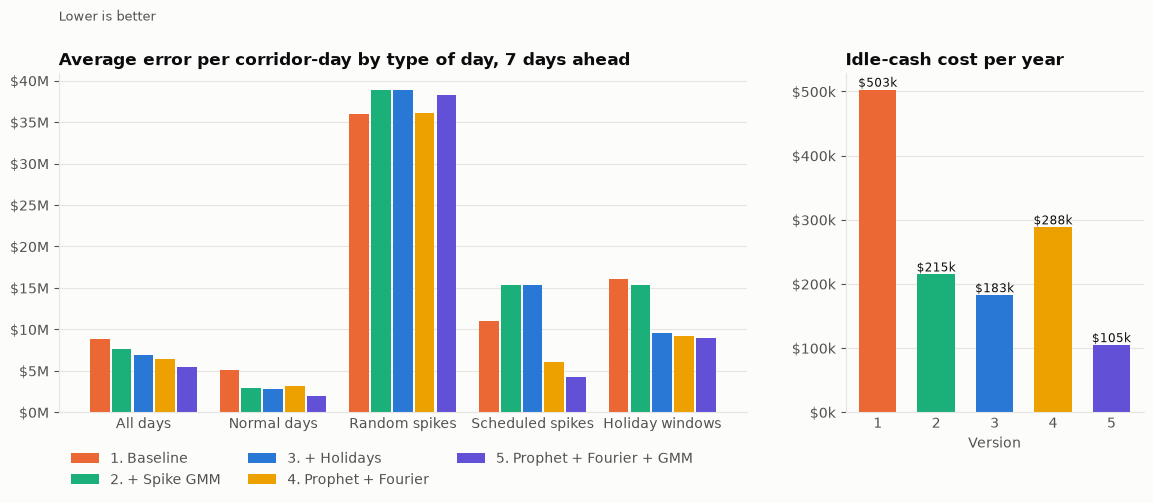

In [14]:
plots.plot_ladder(ladder, 7, None)

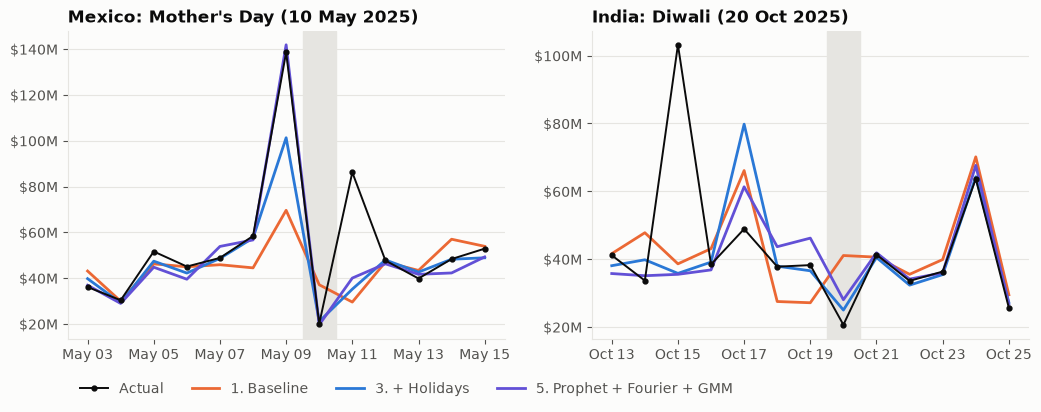

In [15]:
plots.plot_zoom(bt, [('MX', "Mexico: Mother's Day (10 May 2025)", '2025-05-03', '2025-05-15'),
                   ('IN', 'India: Diwali (20 Oct 2025)', '2025-10-13', '2025-10-25')],
                7, ['1. Baseline', '3. + Holidays', '5. Prophet + Fourier + GMM'], None)